# Annotation inventory of the kidney and brain METASPACE collections

This notebook describes the annotation population from which the chemical label graph is built: how many ions are annotated in each image, which METASPACE databases produced them, how often an ion recurs across images, and how ambiguous each annotation is in terms of candidate structures. It answers whether the annotations of the two collections are rich and consistent enough to derive chemical class labels, and how much of the ion vocabulary each local taxonomy can classify at all.

## Introduction

METASPACE identifies an ion by a neutral molecular formula and an adduct and reports, per annotation database, the list of compounds compatible with that formula (`possibleCompounds`). A formula does not determine a structure, so every annotation is a set of candidate structures, and chemical classes of an ion can only be derived from that set. The chemical label graph analysed in the following notebooks connects ions to classes of four taxonomies: LIPID MAPS, SwissLipids, ClassyFire/ChemOnt (through HMDB) and ChEBI.

### Assumptions

- **Collections.** All complete METASPACE images of the workspaces are used: 50 kidney images and 29 brain images (both negative ion mode). The derived `representative_dataset` (two merged kidney sections) is excluded because it is not a METASPACE image.
- **No additional FDR filter.** Annotations are used as exported (FDR ≤ 0.1). A stricter threshold would reduce the vocabulary but not change the definition of classes.
- **Ion identity.** An ion is `formula|adduct`, exactly as in the molecule target vocabulary of the trained models; `C42H82NO8P|-H` and `C42H82NO8P|+Cl` are different ions with the same neutral formula.
- **Candidate resolution.** `metaspace_ids` keeps the candidate compounds reported by METASPACE (translated into each taxonomy through identifiers and cross-references); `formula` admits every compound of the taxonomy with the ion's neutral formula. The second mode does not depend on which annotation database was used, but includes structures that METASPACE never proposed.

### Notation

- $m$ — ion (`formula|adduct`); $\mathcal M$ — ion vocabulary of a collection.
- $T \in \{\mathrm{LM}, \mathrm{SL}, \mathrm{CF}, \mathrm{ChEBI}\}$ — taxonomy (LIPID MAPS, SwissLipids, ClassyFire, ChEBI).
- $S_T(m)$ — candidate compounds of ion $m$ in taxonomy $T$ under a resolution mode.
- $n_{\mathrm{img}}(m)$ — number of images in which $m$ is annotated.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "annotation_inventory"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:55:42,051 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:55:42,054 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:55:42,456 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:55:42,458 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:55:42,465 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:55:42,466 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:55:42,484 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:55:42,498 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:55:42,500 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis annotation_inventory


## Annotation counts per image and annotation database

### Methodology

#### Theoretical

For every image $i$ the number of annotation records and of distinct ions $|\mathcal M_i|$ is counted. Annotations are also counted per METASPACE annotation database (database name and version). Large differences between images mean that the label vocabulary is dominated by a few richly annotated images.

#### Implementation

Counts are taken from `datasets.csv` (one row per image) and `databases.csv` (one row per collection and database) produced by the precompute from every `annotations.csv`. An annotation record is one (image, ion, database) triple; an ion annotated against two databases contributes two records but one ion.

#### Figure descriptions

*Figure 1.* Left: violin of the number of distinct annotated ions per image, one violin per collection, with every image shown as a point. Right: number of annotation records per database (horizontal bars), coloured by collection. Larger values mean more labelled ions; bars are counts, not distributions, because each database occurs once per collection.

collection                   brain   kidney
annotations         count   29.000   50.000
                    mean   199.897   52.060
                    std    203.794   86.863
                    min      1.000    6.000
                    25%     51.000   12.000
                    50%    139.000   17.000
                    75%    276.000   47.500
                    max    971.000  485.000
ions                count   29.000   50.000
                    mean   109.655   36.280
                    std     94.125   55.844
                    min      1.000    4.000
                    25%     36.000    9.000
                    50%     80.000   14.000
                    75%    175.000   37.000
                    max    406.000  311.000
fdr_le_0_05         count   29.000   50.000
                    mean     0.486    0.715
                    std      0.232    0.301
                    min      0.000    0.121
                    25%      0.346    0.475
                    50%      0.450    0.745
                    75%      0.601    1.000
                    max      1.000    1.000
off_sample_fraction count   29.000   50.000
                    mean     0.066    0.178
                    std      0.184    0.151
                    min      0.000    0.000
                    25%      0.000    0.059
                    50%      0.026    0.152
                    75%      0.055    0.250
                    max      1.000    0.588

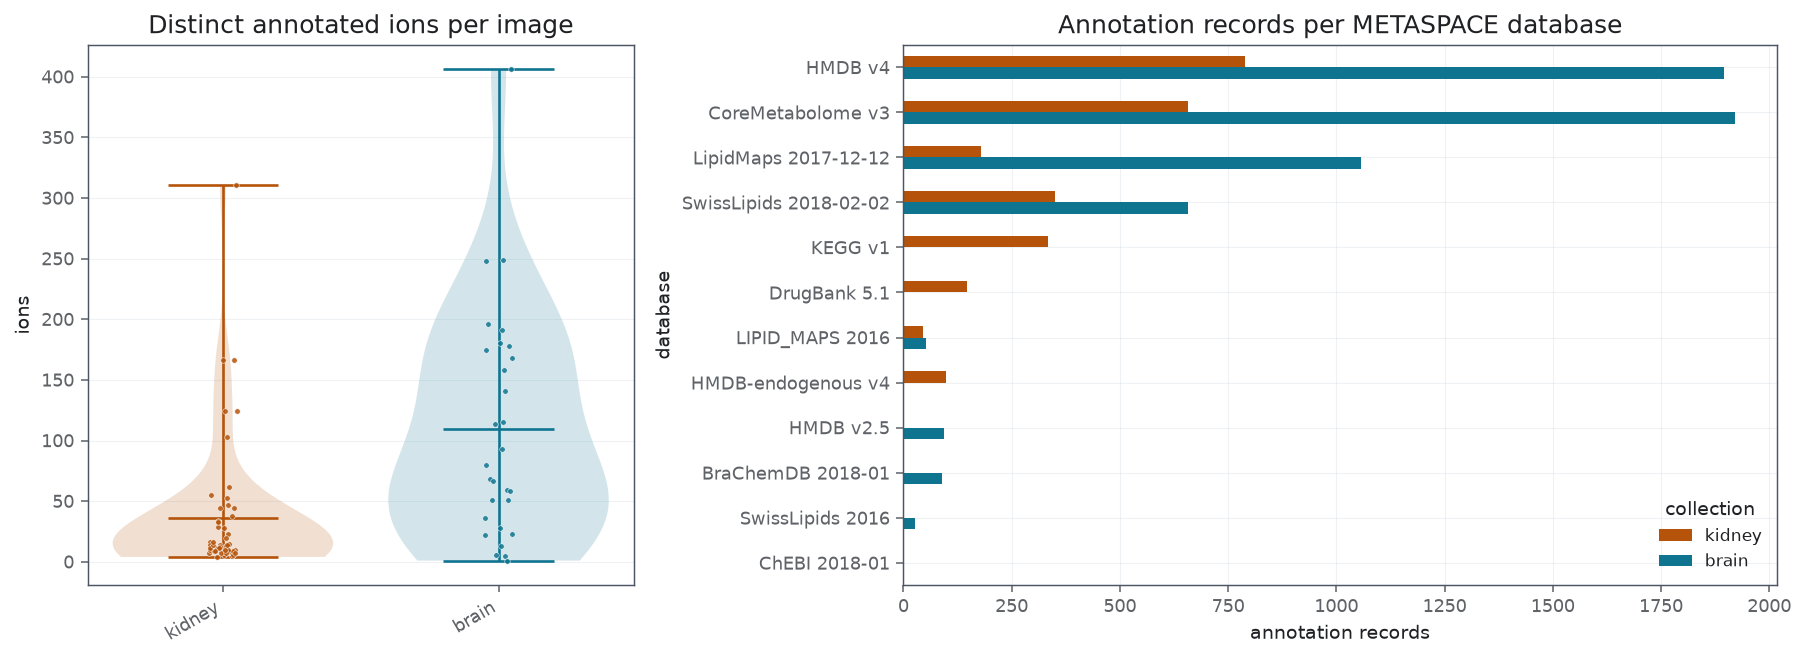

In [2]:
datasets = table("datasets.csv")
databases = table("databases.csv")
display(datasets.groupby("collection")[["annotations", "ions", "fdr_le_0_05", "off_sample_fraction"]].describe().T.round(3))

# --- what this figure shows -------------------------------------------------
VALUE = "ions"            # ions | annotations
TOP_DATABASES = 12
# ---------------------------------------------------------------------------
figure, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
plots.violin_groups(axes[0], datasets, group="collection", value=VALUE, order=COLLECTIONS,
                    colors=plots.COLLECTION_COLORS, theme=THEME)
axes[0].set_title(f"Distinct annotated {VALUE} per image")
pivot = databases.pivot_table(index="database", columns="collection", values="annotations", fill_value=0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index[:TOP_DATABASES]]
pivot[COLLECTIONS].plot.barh(ax=axes[1], color=[plots.COLLECTION_COLORS[c] for c in COLLECTIONS])
axes[1].invert_yaxis()
axes[1].set_xlabel("annotation records")
axes[1].set_title("Annotation records per METASPACE database")
plt.tight_layout()

### Remarks

- Kidney is strongly skewed: median 14 distinct ions per image (IQR 9–37) but one image with 311 ions; a few richly annotated images dominate the kidney vocabulary. Brain: median 80 ions (max 406).
- KEGG and DrugBank annotations exist only in kidney, BraChemDB and HMDB v2.5 only in brain; database choice differs between collections, which affects `metaspace_ids` resolution but not `formula` resolution.
- METASPACE flags a mean of 18 % of kidney annotations per image as off-sample (brain 7 %); they are kept here. Classes driven by off-sample ions would describe background, not tissue.

### Notes

## Recurrence of ions across images

### Methodology

#### Theoretical

The recurrence $n_{\mathrm{img}}(m)$ is the number of images annotating ion $m$. A class label is only learnable when its ions recur; an ion seen in a single image cannot be validated on another image, and pairwise spatial co-localization (part 3) requires two ions annotated in the same image.

#### Implementation

$n_{\mathrm{img}}(m)$ is `dataset_count` in `ions.csv`. The table reports the fraction of ions annotated in exactly one image and in at least three images (the threshold used by the kernel alignment of part 3).

#### Figure descriptions

*Figure 2.* Violin of $\log_{10} n_{\mathrm{img}}(m)$ per collection, every ion as a point (at most 400 seeded points per violin are drawn; the violin uses all ions). Higher values mean ions that recur across more images.

,ions,single_image,at_least_3,median
collection,,,,
brain,904,0.583,0.308,1.0
kidney,862,0.624,0.190,1.0


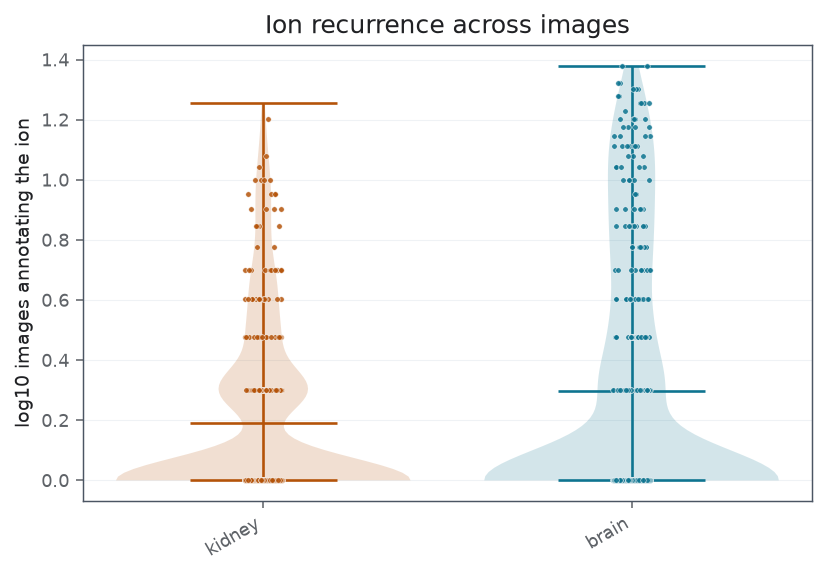

In [3]:
ions = table("ions.csv")
recurrence = ions.groupby("collection").dataset_count.agg(
    ions="size", single_image=lambda v: (v == 1).mean(), at_least_3=lambda v: (v >= 3).mean(), median="median")
display(recurrence.round(3))

# --- what this figure shows -------------------------------------------------
LOG_SCALE = True
# ---------------------------------------------------------------------------
frame = ions.assign(value=np.log10(ions.dataset_count) if LOG_SCALE else ions.dataset_count)
figure, axis = plt.subplots(figsize=(6, 4.2))
plots.violin_groups(axis, frame, group="collection", value="value", order=COLLECTIONS,
                    colors=plots.COLLECTION_COLORS, theme=THEME)
axis.set_ylabel("log10 images annotating the ion" if LOG_SCALE else "images annotating the ion")
axis.set_title("Ion recurrence across images")
plt.tight_layout()

### Remarks

- 62 % of kidney ions and 58 % of brain ions are annotated in a single image; only 19 % (kidney) and 31 % (brain) occur in at least three images. Most molecule labels cannot be validated across images; class labels pool ions and are less affected.

### Notes

## Structural ambiguity of annotations and taxonomy coverage

### Methodology

#### Theoretical

For each taxonomy $T$ and resolution mode, an ion is *resolved* if $|S_T(m)| \ge 1$. Coverage is $|\{m : |S_T(m)| \ge 1\}| / |\mathcal M|$. The candidate count $|S_T(m)|$ measures structural ambiguity: with $|S_T(m)| = 1$ every class of the ion is certain; with many candidates classes can only be certain at coarse levels where all candidates agree (quantified in part 0.2).

The two resolution modes bound the ambiguity: `metaspace_ids` reflects what METASPACE proposed from its annotation database; `formula` reflects every isomer known to the taxonomy.

#### Implementation

Identifiers of `possibleCompounds` are normalized (HMDB accessions to seven digits, LIPID MAPS, SwissLipids, ChEBI, KEGG, DrugBank) and matched against each taxonomy's own identifiers and cross-references; a candidate whose neutral formula differs from the ion formula is discarded. In `formula` mode candidates are all taxonomy compounds with the same canonical neutral (Hill) formula. SwissLipids sub-species are collapsed into their species (sum composition), ChEBI charged entities into their neutral conjugates. Tables: `resolution_coverage.csv`, candidate counts in the `candidates__<taxonomy>__<mode>` columns of `ions.csv`.

#### Figure descriptions

*Figure 3.* Left: coverage (fraction of ions with at least one candidate) per taxonomy; circle = `metaspace_ids`, square = `formula`, colour = collection. Right: violins of $\log_{10}|S_T(m)|$ over resolved ions per taxonomy and resolution mode for the selected collection. Larger coverage means more ions can receive class labels; larger candidate counts mean more ambiguous class assignment.

coverage               median_candidates               unique_candidate_fraction              
resolution              formula metaspace_ids           formula metaspace_ids                   formula metaspace_ids
collection taxonomy                                                                                                  
brain      ChEBI          0.842         0.708               6.0           2.0                     0.193         0.375
           ClassyFire     0.811         0.729               6.0           4.0                     0.168         0.250
           LIPID_MAPS     0.690         0.615               6.0           5.0                     0.159         0.221
           SwissLipids    0.659         0.572               1.0           1.0                     0.508         0.725
kidney     ChEBI          0.874         0.705               7.0           2.0                     0.169         0.396
           ClassyFire     0.818         0.698               5.0           3.0                     0.204         0.347
           LIPID_MAPS     0.516         0.399               7.0           4.0                     0.162         0.270
           SwissLipids    0.474         0.379               1.0           1.0                     0.543         0.761

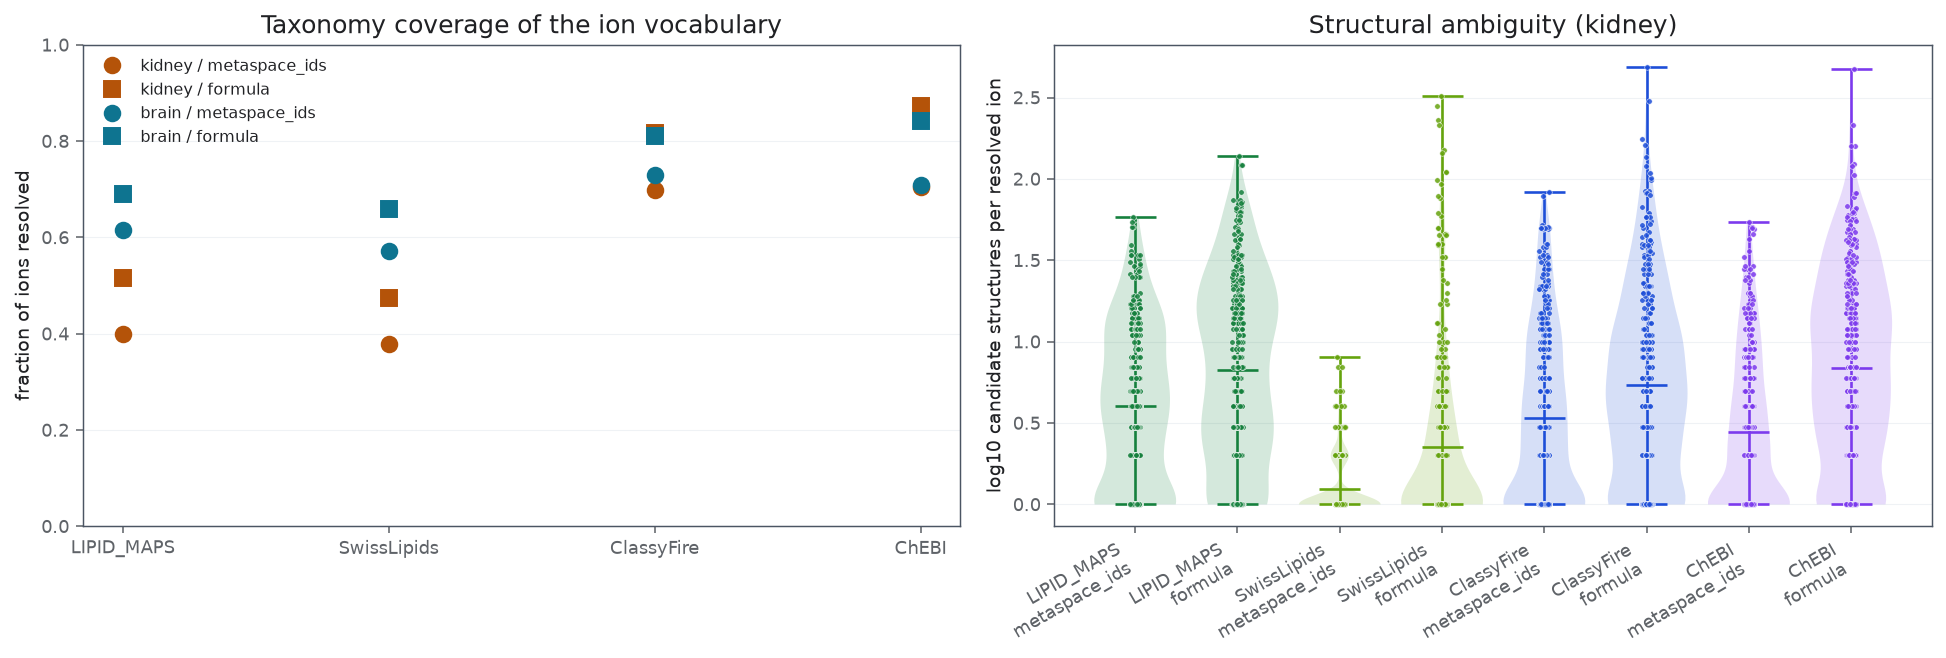

In [4]:
coverage = table("resolution_coverage.csv")
display(coverage.pivot_table(index=["collection", "taxonomy"], columns="resolution",
                             values=["coverage", "median_candidates", "unique_candidate_fraction"]).round(3))

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
# ---------------------------------------------------------------------------
figure, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for collection in COLLECTIONS:
    for resolution, marker in plots.RESOLUTION_STYLES.items():
        rows = coverage[(coverage.collection == collection) & (coverage.resolution == resolution)].set_index("taxonomy").reindex(TAXONOMIES)
        axes[0].plot(range(len(TAXONOMIES)), rows.coverage, marker=marker, linestyle="none", markersize=8,
                     color=plots.COLLECTION_COLORS[collection], label=f"{collection} / {resolution}")
axes[0].set_xticks(range(len(TAXONOMIES)), TAXONOMIES)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("fraction of ions resolved")
axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title("Taxonomy coverage of the ion vocabulary")
subset = ions[ions.collection == COLLECTION]
long = []
for taxonomy in TAXONOMIES:
    for resolution in plots.RESOLUTION_STYLES:
        values = subset[f"candidates__{taxonomy}__{resolution}"]
        long.append(pd.DataFrame({"group": f"{taxonomy}\n{resolution}", "value": np.log10(values[values > 0])}))
long = pd.concat(long)
order = list(dict.fromkeys(long.group))
plots.violin_groups(axes[1], long, group="group", value="value", order=order,
                    colors={g: plots.taxonomy_color(g.split("\n")[0]) for g in order}, theme=THEME)
axes[1].set_ylabel("log10 candidate structures per resolved ion")
axes[1].set_title(f"Structural ambiguity ({COLLECTION})")
plt.tight_layout()

### Remarks

- `formula` resolution covers 82–87 % of ions with ClassyFire/ChEBI, 52 % (kidney) / 69 % (brain) with LIPID MAPS and 47 % / 66 % with SwissLipids; `metaspace_ids` covers 7–17 percentage points fewer ions.
- SwissLipids has a median of one candidate per ion because sub-species are collapsed to sum-composition species; the other taxonomies have medians of 5–7 candidates (`formula`), with tails above 100 candidates.

### Notes

## Results / Summary

### LLM

**Observed.** Kidney: 50 images, 862 ions; brain: 29 images, 904 ions, both negative mode. Most ions occur in one image (kidney 62 %, brain 58 %). Taxonomy coverage with `formula` resolution: ChEBI 87 %/84 %, ClassyFire 82 %/81 %, LIPID MAPS 52 %/69 %, SwissLipids 47 %/66 % (kidney/brain).

**Interpretation.** Broad taxonomies label most ions, lipid taxonomies only the lipid part, which is larger in brain. Only 16–20 % of resolved ions have a single candidate structure (SwissLipids ≈ 50 % after collapsing to species), so class assignment must handle isomer ambiguity explicitly (part 0.2).

**Methodological caveats.** Off-sample annotations are not filtered; annotation databases differ between collections, so `metaspace_ids` results partly reflect database choice.

### Person